# Random number generation

Custom generators built from scratch (no 'numpy.random'):
1. Linear Congruential Generator (LCG) for uniforms
2. Box-Muller transform for standard normals

In [1]:
import sys
sys.path.append("..") # make the src package importable from notebooks/

import numpy as np
import matplotlib.pyplot as plt

from src.rng import LCG

## 1. Linear Congruential Generator

$X_{n+1} = (a * X_n + c) \bmod m$, $U_n = (X_n + 0.5) / m$

In [2]:
rng = LCG(seed=42)

u = rng.uniform(5)
print(u)

[0.25211234 0.53546509 0.25945804 0.63239133 0.41958732]


In [3]:
# Same seed -> same sequence
a = LCG(seed=42).uniform(1000)
b = LCG(seed=42).uniform(1000)
print("Reproductible:", np.array_equal(a, b))

# Two successive calls must continue the same sequence
g = LCG(seed=42)
part1 = g.uniform(500)
part2 = g.uniform(500)
print("Continuous:", np.array_equal(np.concatenate([part1, part2]), a))

Reproductible: True
Continuous: True


In [4]:
u = LCG(seed=42).uniform(1_000_000)

print(f"Mean     : {u.mean():.5f} (theory: 0.50000)")
print(f"Variance : {u.var():.5f} (theory: {1/12:.5f})")
print(f"Min / Max: {u.min():.2e} / {u.max():.6f}")

Mean     : 0.49986 (theory: 0.50000)
Variance : 0.08331 (theory: 0.08333)
Min / Max: 2.51e-06 / 1.000000


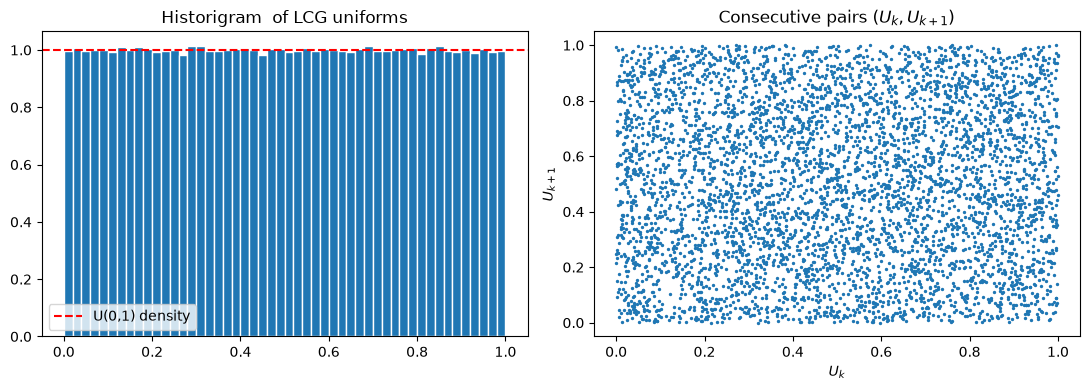

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(u, bins=50, density=True, edgecolor="white")
ax[0].axhline(1.0, color="red", linestyle="--", label="U(0,1) density")
ax[0].set_title("Historigram  of LCG uniforms")
ax[0].legend()

ax[1].scatter(u[:5000-1], u[1:5000], s=2)
ax[1].set_title("Consecutive pairs $(U_k, U_{k+1})$")
ax[1].set_xlabel("$U_k$")
ax[1].set_ylabel("$U_{k+1}$")

plt.tight_layout()
plt.savefig("../figures/lcg_uniform_check.png", dpi=150)

## 2. Box-Muller transform

$Z_1 = \sqrt{-2\ln U_1}\cos(2\pi U_2)$, $Z_2 = \sqrt{-2\ln U_1}\sin(2\pi U_2)$

In [6]:
g = LCG(seed=42)
print(g.normal(5))

# Same seed -> same sequence
a = LCG(seed=42).normal(1001) # odd n on purpose
b = LCG(seed=42).normal(1001)
print("Reproductible:", np.array_equal(a, b), "| length:", len(a))

[-1.11807147 -0.97804296  0.62215886 -1.22706037  0.5409909 ]
Reproductible: True | length: 1001


In [7]:
z = LCG(seed=42).normal(1_000_000)
print(f"Mean     : {z.mean():.5f} (theory: 0)")
print(f"Std dev  : {z.std():.5f} (theory: 1)")
print(f"Skewness : {((z - z.mean())**3).mean() / z.std()**3:.5f} (theory: 0)")
print(f"Kurtosis : {((z - z.mean())**4).mean() / z.std()**4:.5f} (theory: 3)")

Mean     : -0.00029 (theory: 0)
Std dev  : 0.99989 (theory: 1)
Skewness : -0.00133 (theory: 0)
Kurtosis : 2.99492 (theory: 3)


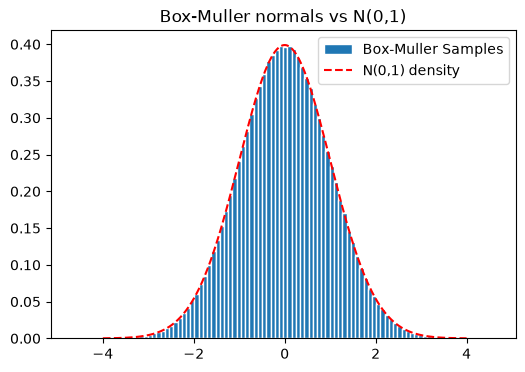

In [8]:
from scipy.stats import norm

x = np.linspace(-4, 4, 400)
plt.figure(figsize=(6, 4))
plt.hist(z, bins=100, density=True, edgecolor="white", label="Box-Muller Samples")
plt.plot(x, norm.pdf(x), "r--", label="N(0,1) density")
plt.title("Box-Muller normals vs N(0,1)")
plt.legend()
plt.show()